
	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 
Healthy vs. cancer

Healthy: 90 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Healthy'): [0, 1]}


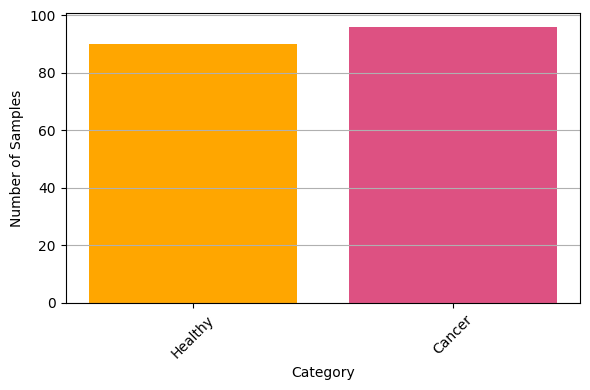


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(186, 31, 7728) (186, 2) (186,)


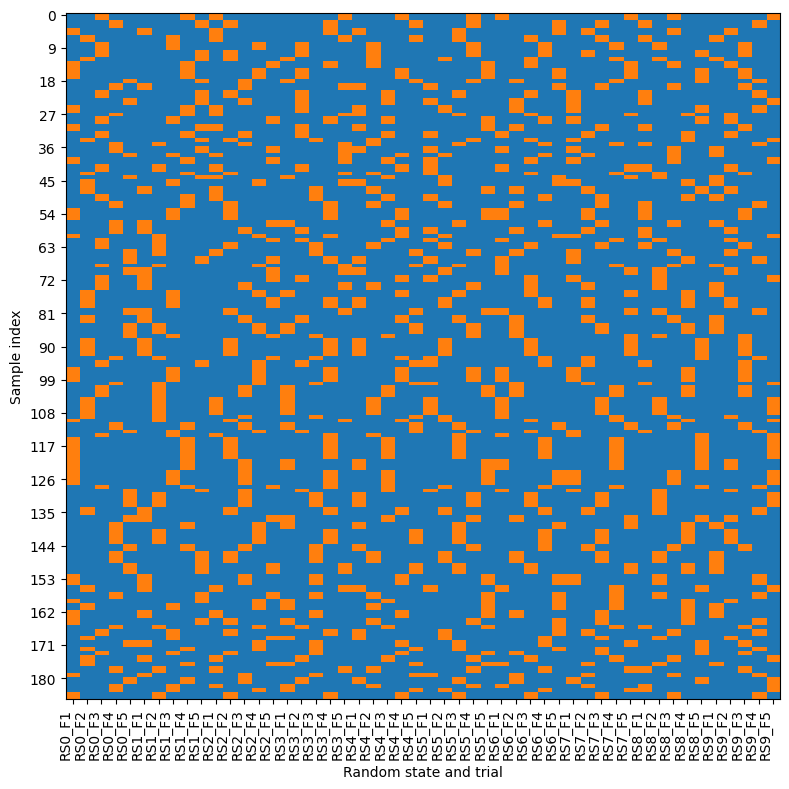

In [1]:
from toolbox.visualization import plot_cv_heatmap
from toolbox.results import Results_data_loading

class_task = "healthy_vs_cancer"

X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False
)

n_trials = 10
n_folds = 5

plot_cv_heatmap(X, Y_labels, Case, n_trials, n_folds)

In [ ]:
# combine IIVV-analysis results
from glob import glob

csv_files = glob(f"results/freq-analysis_*_gpu.csv")
print(csv_files)

In [ ]:
df_list = [pd.read_csv(file) for file in csv_files]
combined_df = pd.concat(df_list, ignore_index=True)

In [ ]:
len(combined_df)

In [ ]:
combined_df

In [ ]:
# combined_df.to_csv(f"results/freq-analysis.csv", index=False)

## Create plots

In [1]:
import pandas as pd
from toolbox.Freq_reduction import (
    plot_fold_rankings_rework,
    plot_no_of_top_frequencies_rework,
    select_random_state,
)

In [ ]:
class_task = "healthy_vs_cancer"
random_state = 1

df = pd.read_csv(f"results/freq-analysis_{class_task}_rework.csv")

In [ ]:
select_random_state(df, random_state)

In [ ]:
plot_fold_rankings_rework(df, random_state, class_task)

In [ ]:
plot_no_of_top_frequencies_rework(df, random_state, class_task)

In [ ]:
import matplotlib.pyplot as plt
from toolbox import get_freqs
from toolbox.Freq_reduction import select_composite_freq_indices

In [ ]:
freq_idx, freq_list = get_freqs(plot=False)

In [ ]:
all_top_freqs_baseline = select_composite_freq_indices(df, random_state)
print(all_top_freqs_baseline)
top_freqs_baseline = [0]

In [ ]:
top_2 = top_freqs_baseline[:2]
top_3 = top_freqs_baseline[:3]
top_5 = top_freqs_baseline[:5]
top_12 = top_freqs_baseline[:12]

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(freq_list[freq_idx], freq_idx, ".", c="#003F5C", ms=6, label="All")
plt.plot(freq_list[top_2], top_2, "o", c="#58508D", ms=9.5, label="Top 2")
plt.plot(freq_list[top_3], top_3, "x", c="#7A5195", ms=9.5, label="Top 3")
plt.plot(freq_list[top_5], top_5, "X", c="#FF6361", ms=8, label="Top 5")
plt.plot(freq_list[top_12], top_12, "*", c="#FFA600", ms=8, label="Top 12")
plt.legend()
plt.grid()
plt.xlabel("Frequency (Hz)")
plt.xscale("log")
plt.ylabel("Frequency index")
plt.tight_layout()
plt.savefig(f"results/freq_topX_{class_task}.pdf", bbox_inches="tight")
plt.show()

### Test top2, top3, top5, top12, all (Baseline)

In [ ]:
Freq_sel = {
    "Top 2": top_2,
    "Top 3": top_3,
    "Top 5": top_5,
    "Top 12": top_12,
    "All": top_freqs_baseline,  # np.arange(31), # it doesn't matter
}

In [ ]:
results = []
numXparams = []
for Fsel, idxs in Freq_sel.items():
    numXparams.append({"Fsel": Fsel, "n_params": len(X[0, idxs, :].flatten())})
    for trial in range(7):
        print("Trial:", trial, "\n\t", Fsel, idxs)

        avg_roc_auc, _ = compute_ROC_patient_split(
            X[:, idxs, :],
            Y,
            patient_ids=Case,
            test_size=0.2,
            plot=False,
            random_state=trial,
            inverse_mapping=inverse_mapping,
        )

        results.append({"Fsel": Fsel, "Trial": trial + 1, "avg. ROC AUC": avg_roc_auc})


df_results = pd.DataFrame(results)
df_params = pd.DataFrame(numXparams)

df_results.to_csv(f"results/freq-analysis_{class_task}.csv", index=False)
df_params.to_csv(f"results/freq-analysis_{class_task}_params.csv", index=False)

In [ ]:
plt.figure(figsize=(6, 3))
sns.heatmap(
    df_pivot, annot=True, cmap=cmap, fmt=".2f", cbar_kws={"label": "avg. ROC AUC"}
)

plt.ylabel("Selected frequencies")
plt.xlabel("Trial")
plt.tight_layout()
# title: Average AUC Heatmap
# plt.savefig("results/auc_heatmap_freq_sel.pdf", bbox_inches="tight")
plt.show()

In [ ]:
df_results = pd.read_csv(f"results/freq-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/freq-analysis_{class_task}_params.csv")

In [ ]:
df_pivot = df_results.pivot(index="Fsel", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Fsel", "avg. ROC AUC"]
df_plot = pd.merge(df_params, df_results_avg, on="Fsel")

fig = plt.figure(figsize=(9, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
order = ["Top 2", "Top 3", "Top 5", "Top 12", "All"]  # defined order
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "Mean AUC"}, ax=ax0
)
ax0.set_ylabel("Selected frequencies")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Average AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg. ROC AUC"],
        ".",
        label=row["Fsel"],
        markersize=8,
    )
ax1.set_xlabel("Input data points $N_{input}$\n(b)")
# ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
# ax1.set_xscale('log')

ax1.legend(title="Freq. selection")
plt.savefig(f"results/freq_sel_perf_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [ ]:
df_plot

___

**Code for statistical evaluation of the impact of $\mathbf{f}_\mathrm{T}$**

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import auc, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import label_binarize
from sklearn.svm import SVC
from toolbox.evaluation import load_top_Fsel_Msel
from toolbox.results import Results_data_loading
from tqdm import tqdm

In [ ]:
class_task = "healthy_vs_cancer"

stats = []

Freq_sel, _ = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False
)
print(Freq_sel)
for Fsel in Freq_sel.keys():
    X_tmp = X[:, Freq_sel[Fsel], :]
    X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
    for rs in tqdm(range(20)):
        m = SVC(probability=True, random_state=0)
        cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)
        for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
            X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
            y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
            m.fit(X_train, y_train)
            probs = m.predict_proba(X_test)[:, 1]
            auc = roc_auc_score(y_test, probs)
            stats.append({"Task": class_task, "Fsel": Fsel, "rs": rs, "auc": auc})

df_stats = pd.DataFrame(stats)
df_stats.to_csv(f"results/freq-analysis_{class_task}_statistics.csv", index=False)

In [ ]:
class_task = "cancer_vs_hbd"

stats = []

Freq_sel, _ = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False
)
print(Freq_sel)
for Fsel in Freq_sel.keys():
    X_tmp = X[:, Freq_sel[Fsel], :]
    X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
    for rs in tqdm(range(20)):
        m = SVC(probability=True, random_state=0)
        cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)
        for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
            X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
            y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
            m.fit(X_train, y_train)
            probs = m.predict_proba(X_test)[:, 1]
            auc = roc_auc_score(y_test, probs)
            stats.append({"Task": class_task, "Fsel": Fsel, "rs": rs, "auc": auc})

df_stats = pd.DataFrame(stats)
df_stats.to_csv(f"results/freq-analysis_{class_task}_statistics.csv", index=False)

In [ ]:
class_task = "MC"

stats = []

Freq_sel, _ = load_top_Fsel_Msel(class_task)
X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
    class_task, data_augmentation=False
)
classes = np.unique(Y_labels)
print(Freq_sel)
for Fsel in Freq_sel.keys():
    X_tmp = X[:, Freq_sel[Fsel], :]
    X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
    for rs in tqdm(range(20)):
        m = SVC(probability=True, random_state=0)
        cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)
        for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
            X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
            y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
            m.fit(X_train, y_train)
            probs = m.predict_proba(X_test)  # shape (n_samples, n_classes)
            # Binarize true labels
            y_bin = label_binarize(
                y_test, classes=classes
            )  # shape (n_samples, n_classes)
            # Micro-average ROC
            fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
            roc_auc = auc(fpr, tpr)

            # Flip AUC if < 0.5
            if roc_auc < 0.5:
                fpr, tpr = 1 - fpr, 1 - tpr
                roc_auc = 1 - roc_auc

            stats.append({"Task": class_task, "Fsel": Fsel, "rs": rs, "auc": roc_auc})

df_stats = pd.DataFrame(stats)
df_stats.to_csv(f"results/freq-analysis_{class_task}_statistics.csv", index=False)

In [ ]:
tasks = ["healthy_vs_cancer", "cancer_vs_hbd", "MC"]

stats = []
Fsel = "All"

for class_task in tasks:
    print(class_task)
    X, Y_labels, labels, Case, inverse_mapping, Y = Results_data_loading(
        class_task, data_augmentation=False
    )
    classes = np.unique(Y_labels)
    n_classes = len(classes)

    X_tmp = X[:, :, :]
    X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)
    for rs in tqdm(range(20)):
        m = SVC(probability=True, random_state=0)
        cv = GroupKFold(n_splits=5, shuffle=True, random_state=rs)
        for train_idx, test_idx in cv.split(X_tmp, Y_labels, Case):
            X_train, X_test = X_tmp[train_idx], X_tmp[test_idx]
            y_train, y_test = Y_labels[train_idx], Y_labels[test_idx]
            m.fit(X_train, y_train)
            probs = m.predict_proba(X_test)
            if n_classes == 2:
                roc_auc = roc_auc_score(y_test, probs[:, 1])
            else:
                y_bin = label_binarize(y_test, classes=classes)
                # Micro-average ROC
                fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
                roc_auc = auc(fpr, tpr)

                # Flip AUC if < 0.5
                if roc_auc < 0.5:
                    fpr, tpr = 1 - fpr, 1 - tpr
                    roc_auc = 1 - roc_auc

            stats.append({"Task": class_task, "Fsel": Fsel, "rs": rs, "auc": roc_auc})

df_stats = pd.DataFrame(stats)
df_stats.to_csv(f"results/freq-analysis_{class_task}_ALL_statistics.csv", index=False)

___